# 📊 Factory Statistics Analysis
**Author:** Ayush Ramtekkar · **Tools:** Python, pandas, matplotlib

**Question:** What is a *typical* machine in our factory, how different are the machines, and what drives repair and energy costs?

Data:
- `factory.csv`: 10 machines (type, power, daily hours, operating temperature)
- repair costs per machine (from my [SQL maintenance project](https://github.com/ayushramtekkar/Factory_maintenance_SQL))
- `monthly_energy.csv`: monthly energy use and approximate outside temperature

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

BLUE = "#2a78d6"
df = pd.read_csv("factory.csv")
df["repair_cost_eur"] = [1070, 0, 0, 0, 0, 900, 210, 90, 540, 680]   # total repairs per machine (SQL project, Q7)
m = pd.read_csv("monthly_energy.csv")
df

,machine,type,power_kw,hours,temp_c,repair_cost_eur
0,Compressor A,compressor,7.5,8,95,1070
1,Pump B,pump,1.5,10,60,0
2,Fan C,fan,0.1,5,20,0
3,Drill D,drill,0.5,8,50,0
4,Oven E,oven,4.0,6,88,0
5,Chiller F,chiller,3.2,12,92,900
6,Pump G,pump,2.2,16,71,210
7,Fan H,fan,0.3,24,35,90
8,Compressor I,compressor,5.5,10,83,540
9,Oven J,oven,6.0,4,97,680


## 1. The middle: mean vs median

In [2]:
print("Mean temperature:  ", df["temp_c"].mean())
print("Median temperature:", df["temp_c"].median())

Mean temperature:   69.1
Median temperature: 77.0


💡 **Insight:** the mean (69.1 °C) is lower than the median (77 °C). Two cold fans (20 °C and 35 °C) pull the average down, while most machines run hot.

### What one outlier does (what-if scenario)

In [3]:
costs = pd.Series([450, 620, 380, 900, 210, 540, 300, 90])           # the 8 real repairs
costs_big = pd.Series([450, 620, 380, 900, 210, 540, 300, 90, 5000])  # + one hypothetical 5,000 EUR breakdown
pd.DataFrame({"mean": [costs.mean(), costs_big.mean()],
              "median": [costs.median(), costs_big.median()],
              "std": [costs.std(), costs_big.std()]},
             index=["8 repairs", "+ 5,000 EUR outlier"]).round(1)

,mean,median,std
8 repairs,436.2,415.0,254.3
"+ 5,000 EUR outlier",943.3,450.0,1539.7


💡 **Insight:** one extreme repair more than doubles the mean (436 → 943 EUR) and multiplies the standard deviation by 6, while the median barely moves (415 → 450 EUR). **With outliers, report the median.**

### Most common issue (mode)

In [4]:
issues = pd.Series(["overheating", "valve", "overheating", "refrigerant",
                    "seal", "overheating", "sensor", "belt"])
print(issues.value_counts())
print("Mode:", issues.mode()[0])

overheating    3
valve          1
refrigerant    1
seal           1
sensor         1
belt           1
Name: count, dtype: int64
Mode: overheating


## 2. The spread

In [5]:
df[["temp_c", "hours", "power_kw"]].describe().round(2)

,temp_c,hours,power_kw
count,10.00,10.00,10.00
mean,69.10,10.30,3.08
std,26.98,5.96,2.61
min,20.00,4.00,0.10
25%,52.50,6.50,0.75
50%,77.00,9.00,2.70
75%,91.00,11.50,5.12
max,97.00,24.00,7.50


💡 **Insight:** temperatures vary a lot (std ≈ 27 °C): the middle half of the machines runs between 52.5 and 91 °C.

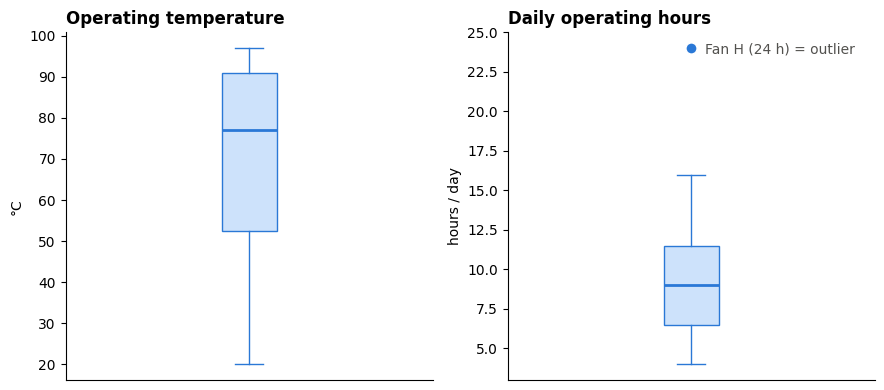

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
bp = dict(patch_artist=True, boxprops=dict(facecolor="#cde2fb", color=BLUE),
          medianprops=dict(color=BLUE, linewidth=2), whiskerprops=dict(color=BLUE),
          capprops=dict(color=BLUE), flierprops=dict(marker="o", markerfacecolor=BLUE, markeredgecolor="white", markersize=8))
axes[0].boxplot(df["temp_c"], **bp)
axes[0].set_title("Operating temperature", loc="left", fontweight="bold")
axes[0].set_ylabel("°C")
axes[1].boxplot(df["hours"], **bp)
axes[1].set_title("Daily operating hours", loc="left", fontweight="bold")
axes[1].set_ylabel("hours / day")
axes[1].annotate("Fan H (24 h) = outlier", (1, 24), textcoords="offset points", xytext=(10, -4), color="#52514e")
for ax in axes:
    ax.set_xticks([])
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("boxplots.png", dpi=150)
plt.show()

💡 **Insight:** the temperature box sits high, so most machines run hot. Fan H (24 h/day) is an outlier in operating hours (above the 1.5 × IQR limit of 19 h).

## 3. Relationships: correlation

In [7]:
print("temp_c vs repair cost:  ", round(df["temp_c"].corr(df["repair_cost_eur"]), 2))
print("power_kw vs repair cost:", round(df["power_kw"].corr(df["repair_cost_eur"]), 2))
print("temp_c vs power_kw:     ", round(df["temp_c"].corr(df["power_kw"]), 2))

temp_c vs repair cost:   0.72
power_kw vs repair cost: 0.79
temp_c vs power_kw:      0.87


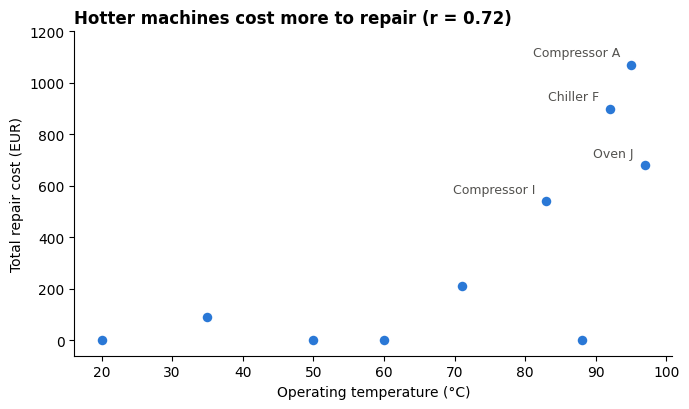

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(df["temp_c"], df["repair_cost_eur"], s=70, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
for _, r in df[df["repair_cost_eur"] > 500].iterrows():
    ax.annotate(r["machine"], (r["temp_c"], r["repair_cost_eur"]), textcoords="offset points",
                xytext=(-8, 6), ha="right", fontsize=9, color="#52514e")
ax.set_title("Hotter machines cost more to repair (r = 0.72)", loc="left", fontweight="bold")
ax.set_xlabel("Operating temperature (°C)")
ax.set_ylabel("Total repair cost (EUR)")
ax.set_ylim(-60, 1200)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("temp_vs_repair_cost.png", dpi=150)
plt.show()

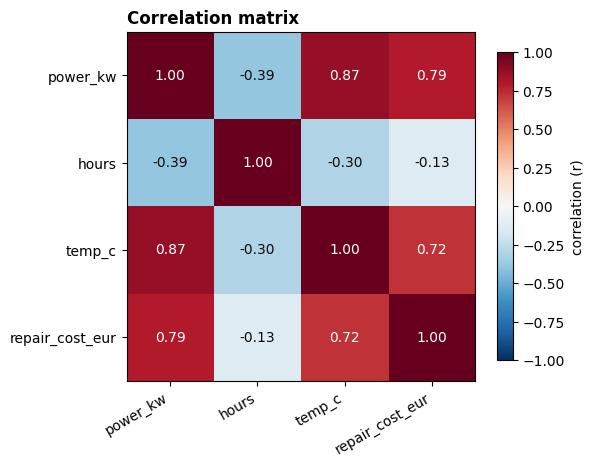

In [9]:
corr = df[["power_kw", "hours", "temp_c", "repair_cost_eur"]].corr().round(2)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(corr.columns, rotation=30, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(corr.columns)
for i in range(4):
    for j in range(4):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.set_title("Correlation matrix", loc="left", fontweight="bold")
fig.colorbar(im, ax=ax, shrink=0.8, label="correlation (r)")
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=150)
plt.show()

💡 **Insight:** temperature and repair cost are strongly correlated (r = 0.72), but temperature is also strongly linked to machine size (r = 0.87 with power). **Correlation is not causation**: machine size may drive both heat and repairs. Daily operating hours barely relate to repair cost (r = −0.13).

## 4. A trap: r ≈ 0 does not mean no relationship

In [10]:
print("energy vs outside temperature: r =", round(m["energy_kwh"].corr(m["outside_temp_c"]), 2))
m.sort_values("energy_kwh", ascending=False).head(3)

energy vs outside temperature: r = -0.04


,month,energy_kwh,outside_temp_c
7,Aug,10200,19
6,Jul,9900,20
0,Jan,9800,0


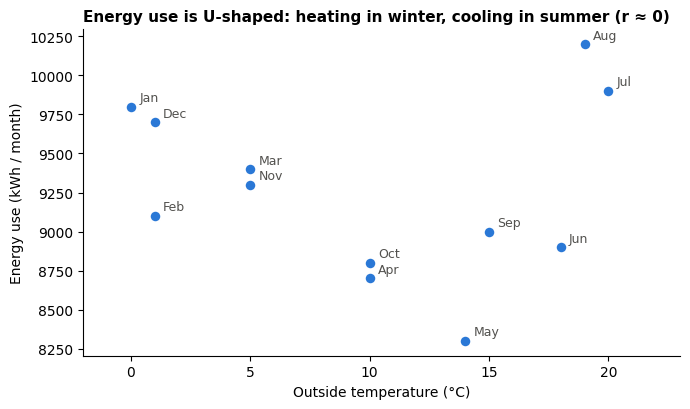

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(m["outside_temp_c"], m["energy_kwh"], s=70, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
for _, r in m.iterrows():
    ax.annotate(r["month"], (r["outside_temp_c"], r["energy_kwh"]), textcoords="offset points",
                xytext=(6, 4), fontsize=9, color="#52514e")
ax.set_title("Energy use is U-shaped: heating in winter, cooling in summer (r ≈ 0)", loc="left", fontweight="bold", fontsize=11)
ax.set_xlabel("Outside temperature (°C)")
ax.set_ylabel("Energy use (kWh / month)")
ax.set_xlim(-2, 23)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("energy_u_shape.png", dpi=150)
plt.show()

💡 **Insight:** the correlation is almost zero (−0.04), yet the plot shows a clear U-shape: energy peaks in winter (heating) and summer (cooling) and is lowest in spring. Correlation only measures straight-line relationships, so **always plot the data first**.

## ✅ Conclusions
1. **Most machines run hot** (median 77 °C); two cold fans pull the average down.
2. **Report medians when outliers exist**: one extreme repair doubles the mean.
3. **Hot, powerful machines cost the most to repair** (r = 0.72 / 0.79), but size and heat go together, so more data is needed before concluding that heat itself causes repairs.
4. **Energy demand is seasonal and U-shaped**, so plan for both heating and cooling peaks.